# What Matters to a Mind?

*The Mathematics of Machine Intelligence · Chapter 13*

Give a machine a way to value outcomes, and see what each way builds in.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what the outcomes are measured from (wealth, a reference point, a bodily state, or a person's comparisons), then choose the matching card: the logarithm when the same gain should matter less to someone who has more, the reference-point curve when framing as gain or loss may change the choice, the drive model when the body's needs change a goal's worth, the comparison rule when only a person can say which of two outcomes is better. Say which part of the rule does the work, what the person or designer chose, and what choices would show the rule is wrong for this case.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 13, What Matters to a Mind?: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def legend_below(ax, ncol=3):
    ax.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=ncol)
GAIN = 1000.0
PRIZE = 20000.0
BERNOULLI_SALE = 9000.0

def log_gain(start, gain=GAIN, b=1.0):
    """Bernoulli's score y = b ln(x / x0) for a gain from starting wealth x0 (needs x0 > 0)."""
    if not start > 0:
        raise ValueError('Starting wealth must be above zero.')
    return b * math.log((start + gain) / start)

def ticket_worth(wealth, prize=PRIZE):
    """Certain amount p with ln(w + p) = 1/2 ln(w) + 1/2 ln(w + prize), for a ticket paying 0 or prize."""
    if not wealth > 0:
        raise ValueError('Wealth must be above zero.')
    return math.sqrt(wealth * (wealth + prize)) - wealth

def log_picture(start_wealth=1000):
    ok = start_wealth > 0
    fig, ax = panels()
    grid = np.geomspace(50, 300000, 300)
    ax[0].plot(grid, [log_gain(w) for w in grid], color=TEAL, linewidth=2.5)
    ax[0].set_xscale('log')
    ax[0].set(xlabel='starting wealth (ducats, log scale)', ylabel='score of a 1,000 ducat gain (b = 1)', title='A gain scores less when richer', ylim=(0, 3.2))
    ax[1].plot(grid, [ticket_worth(w) for w in grid], color=TEAL, linewidth=2.5, label='worth of the ticket')
    ax[1].axhline(PRIZE / 2, color=GREY, linestyle='dotted', linewidth=1.3, label='average prize, 10,000')
    ax[1].axhline(BERNOULLI_SALE, color=GOLD, linestyle='dashed', linewidth=1.6, label='the 9,000 price')
    ax[1].set_xscale('log')
    ax[1].set(xlabel='starting wealth (ducats, log scale)', ylabel='certain amount worth the same (ducats)', title='A ticket is worth more when richer', ylim=(0, 11000))
    if ok:
        ring(ax[0], start_wealth, log_gain(start_wealth))
        tag(ax[0], start_wealth * 1.35, log_gain(start_wealth) + 0.3, sig(log_gain(start_wealth)), va='bottom', ha='left', color=NAVY)
        ring(ax[1], start_wealth, ticket_worth(start_wealth))
    else:
        for a in ax:
            a.text(0.5, 0.5, 'wealth 0:\nlogarithm undefined', transform=a.transAxes, ha='center', va='center', fontsize=11, color=TERRA, bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9})
    legend_below(ax[1], ncol=1)
    if ok:
        score = log_gain(start_wealth)
        worth = ticket_worth(start_wealth)
        if abs(worth - BERNOULLI_SALE) < 1e-06:
            verdict = 'equal to the 9,000 price'
        elif worth < BERNOULLI_SALE:
            verdict = 'below 9,000: selling at 9,000 is no mistake'
        else:
            verdict = 'above 9,000: buying at 9,000 is no mistake'
        metrics = {'Score of a 1,000 ducat gain': sig(score), 'Wealth after the gain (ducats)': sig(start_wealth + GAIN, 6), 'Worth of the ticket (ducats)': sig(worth, 4), 'Worth against 9,000': verdict}
        summary = f'Starting from {start_wealth:,.0f} ducats, a 1,000 ducat gain scores {sig(score)}. The ticket, which pays 0 or 20,000 with equal chances, is worth {sig(worth, 4)} certain ducats to this holder, {verdict}.'
        calc = f'Gain score = ln(({start_wealth:,.0f} + 1,000)/{start_wealth:,.0f}) = {sig(score)}. Ticket worth p solves ln(w + p) = 0.5 ln(w) + 0.5 ln(w + 20,000), so p = sqrt(w (w + 20,000)) - w = {sig(worth, 4)}.'
    else:
        metrics = {'Score of a 1,000 ducat gain': 'undefined (the logarithm needs wealth above zero)', 'Wealth after the gain (ducats)': '1000', 'Worth of the ticket (ducats)': 'undefined (the logarithm needs wealth above zero)', 'Worth against 9,000': 'undefined'}
        summary = 'With no starting wealth, the logarithm of the ratio of wealth after to wealth before is undefined, so the rule gives no score for the gain and no worth for the ticket.'
        calc = 'ln((0 + 1,000)/0) divides by zero; both wealth amounts must be above zero.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PROBLEMS = ['gain frame', 'loss frame', 'even bet']

def value_curve(x, loss_weight=2.0):
    """The chapter's constructed curve: sqrt(x) for gains, minus loss_weight x sqrt(-x) for losses."""
    if x >= 0:
        return math.sqrt(x)
    return -loss_weight * math.sqrt(-x)

def prospect_scores(problem, loss_weight=2.0):
    """(certain option score, gamble score) for one of the three constructed problems."""
    v = lambda x: value_curve(x, loss_weight)
    if problem == 'gain frame':
        return (v(500), 0.5 * v(1000) + 0.5 * v(0))
    if problem == 'loss frame':
        return (v(-500), 0.5 * v(-1000) + 0.5 * v(0))
    if problem == 'even bet':
        return (v(0), 0.5 * v(500) + 0.5 * v(-500))
    raise ValueError(problem)
OPTION_LABELS = {'gain frame': ('certain\n+500', 'gamble:\n+1,000 or 0'), 'loss frame': ('certain\n-500', 'gamble:\n-1,000 or 0'), 'even bet': ('certain\nchange of 0', 'gamble:\n+500 or -500')}
STUDY = {'gain frame': 'certain gain (84 percent of 70 chose it)', 'loss frame': 'the gamble (31 percent of 68 chose the certain loss)', 'even bet': 'not tested in the chapter'}

def value_picture(problem='gain frame', loss_weight=2.0):
    certain, gamble = prospect_scores(problem, loss_weight)
    diff = gamble - certain
    if abs(diff) < 1e-09:
        choice = 'tie (equal scores)'
    else:
        choice = 'the gamble' if diff > 0 else 'the certain option'
    fig, ax = panels()
    labels = OPTION_LABELS[problem]
    values = [certain, gamble]
    bars = ax[0].bar(labels, values, color=[TEAL, TERRA], width=0.55)
    span = max(abs(certain), abs(gamble), 20)
    for bar, val in zip(bars, values):
        tag(ax[0], bar.get_x() + bar.get_width() / 2, val + (0.05 * span if val >= 0 else -0.05 * span), sig(val), va='bottom' if val >= 0 else 'top')
    ax[0].axhline(0, color=GREY, linewidth=1)
    ax[0].set(ylabel='score (arbitrary units)', title=f'{problem.capitalize()}: the two options', ylim=(-1.3 * span, 0.3 * span) if min(values) < 0 else (-0.05 * span, 1.3 * span))
    lam = np.linspace(0.5, 3.5, 61)
    styles = {'gain frame': (TEAL, 'solid'), 'loss frame': (TERRA, 'dashed'), 'even bet': (DARK_GOLD, 'dotted')}
    for name in PROBLEMS:
        colour, style = styles[name]
        curve = [prospect_scores(name, L)[1] - prospect_scores(name, L)[0] for L in lam]
        chosen = name == problem
        ax[1].plot(lam, curve, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=name)
    ax[1].axhline(0, color=GREY, linewidth=1)
    ring(ax[1], loss_weight, diff)
    ax[1].text(3.45, 0.6, 'gamble ahead', ha='right', va='bottom', fontsize=9, color=GREY)
    ax[1].text(3.45, -0.6, 'certain option ahead', ha='right', va='top', fontsize=9, color=GREY)
    ax[1].set(xlabel='loss weight (1 means no extra weight on losses)', ylabel='gamble score minus certain score', title='Only the even bet depends on the loss weight')
    legend_below(ax[1])
    metrics = {'Score of the certain option': sig(certain), 'Score of the gamble': sig(gamble), 'Model picks': choice, 'Majority in the study': STUDY[problem]}
    summary = f"With loss weight {sig(loss_weight)}, the certain option scores {sig(certain)} and the gamble {sig(gamble)}, so the model picks {choice}. The curve is the chapter's constructed illustration, not fitted to the respondents."
    names = {'gain frame': 'sqrt(500) versus half of sqrt(1,000)', 'loss frame': f'-{sig(loss_weight)} sqrt(500) versus half of -{sig(loss_weight)} sqrt(1,000)', 'even bet': f'0 versus half of sqrt(500) minus half of {sig(loss_weight)} sqrt(500)'}
    calc = f'{names[problem]}: {sig(certain)} against {sig(gamble)}. Scores are averaged with the stated chances, with no probability weighting.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
SET_POINT = 10.0
OUTCOME = 3.0

def drive(levels, set_points=(SET_POINT, SET_POINT), n=1.0, m=1.0):
    """D = (sum |h_star - h|^n)^(1/m)."""
    return float(sum((abs(s - h) ** n for s, h in zip(set_points, levels))) ** (1.0 / m))

def drive_reward(levels, change, n=1.0, m=1.0):
    """r = D(H) - D(H + K)."""
    after = [h + k for h, k in zip(levels, change)]
    return drive(levels, n=n, m=m) - drive(after, n=n, m=m)
FORMS = {1: (1.0, 1.0), 2: (3.0, 2.0)}

def drive_picture(food=4, water=10, form=1):
    n, m = FORMS[form]
    levels = (float(food), float(water))
    d0 = drive(levels, n=n, m=m)
    r_food = drive_reward(levels, (OUTCOME, 0.0), n, m)
    r_water = drive_reward(levels, (0.0, OUTCOME), n, m)
    d_food = d0 - r_food
    d_water = d0 - r_water
    fig, ax = panels()
    width = 0.34
    ax[0].bar([0 - width / 2], [d0], width, color=GREY, label='drive before')
    ax[0].bar([1 - width / 2], [d0], width, color=GREY)
    ax[0].bar([0 + width / 2], [d_food], width, color=TEAL, label='drive after')
    ax[0].bar([1 + width / 2], [d_water], width, color=TEAL)
    top = max(d0, d_food, d_water, 1) * 1.3
    for x, val in [(-width / 2, d0), (width / 2, d_food), (1 - width / 2, d0), (1 + width / 2, d_water)]:
        tag(ax[0], x, val + top * 0.02, sig(val), va='bottom')
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels(['3 units of food', '3 units of water'])
    ax[0].set(ylabel='drive (distance from set points)', title=f'Drive at food {food:g}, water {water:g}', ylim=(0, top))
    legend_below(ax[0], ncol=2)
    levels_grid = np.linspace(0, 12, 121)
    rf = [drive_reward((f, float(water)), (OUTCOME, 0.0), n, m) for f in levels_grid]
    rw = [drive_reward((f, float(water)), (0.0, OUTCOME), n, m) for f in levels_grid]
    ax[1].plot(levels_grid, rf, color=TEAL, linewidth=2.5, label='reward of 3 units of food')
    ax[1].plot(levels_grid, rw, color=TERRA, linewidth=2.5, linestyle='dashed', label='reward of 3 units of water')
    ax[1].axhline(0, color=GREY, linewidth=1)
    ax[1].axvline(SET_POINT, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].text(SET_POINT + 0.15, 1.5, 'food\nset point', fontsize=9, color=GREY, va='center', ha='left')
    ring(ax[1], food, r_food)
    ax[1].plot([food], [r_water], marker='s', markersize=9, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.0, zorder=6)
    ax[1].set(xlabel=f'current food level (water held at {water:g})', ylabel='reward = drive before minus drive after', title='Food rewards a hungry body only')
    legend_below(ax[1], ncol=1)
    if r_food > r_water + 1e-09:
        better = 'food'
    elif r_water > r_food + 1e-09:
        better = 'water'
    else:
        better = 'neither (equal rewards)'
    metrics = {'Drive before': sig(d0), 'Reward of 3 units of food': sig(r_food), 'Reward of 3 units of water': sig(r_water), 'Higher reward': better}
    form_text = 'n = m = 1, drive is the sum of the gaps' if form == 1 else 'n = 3, m = 2, so drive is the square root of the sum of cubed gaps'
    summary = f"At food {food:g} and water {water:g} the model body's drive is {sig(d0)}. Three units of food score {sig(r_food)} and three units of water {sig(r_water)}, so {better} scores higher. This is a constructed model, not a fit to any animal."
    calc = f'Set points 10 and 10; {form_text}. Drive now = {sig(d0)}. After food: ({food + OUTCOME:g}, {water:g}) gives {sig(d_food)}, reward {sig(d0)} - {sig(d_food)} = {sig(r_food)}. After water: ({food:g}, {water + OUTCOME:g}) gives {sig(d_water)}, reward {sig(r_water)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def prefer_probability(score_a, score_b, random_response=0.0):
    """P(a preferred) = e^ra / (e^ra + e^rb), mixed with a fair coin for a share of random responses."""
    gap = score_a - score_b
    base = 1.0 / (1.0 + math.exp(-gap))
    return (1 - random_response) * base + random_response * 0.5

def comparison_picture(score_a=2, score_b=1, random_response=0.0):
    p = prefer_probability(score_a, score_b, random_response)
    gap = score_a - score_b
    fig, ax = panels()
    d = np.linspace(-5, 5, 201)
    ax[0].plot(d, [prefer_probability(x, 0, 0.0) for x in d], color=TEAL, linewidth=2.2, label='rule alone')
    ax[0].plot(d, [prefer_probability(x, 0, 0.1) for x in d], color=GOLD, linewidth=2.2, linestyle='dashed', label='with 10 percent random responses')
    ax[0].axhline(0.5, color=GREY, linewidth=1, linestyle='dotted')
    ring(ax[0], gap, p)
    tag(ax[0], gap, p - 0.09 if gap > 0 else p + 0.09, sig(p), color=NAVY, va='center')
    ax[0].set(xlabel='score of A minus score of B', ylabel='chance A is preferred', title='A bigger gap, a surer preference', ylim=(-0.03, 1.03))
    legend_below(ax[0], ncol=1)
    grid = np.linspace(-0.5, 4.5, 101)
    for other, style, colour in [(0, 'solid', TEAL), (1, 'dashed', GOLD), (2, 'dotted', TERRA)]:
        chosen = other == score_b
        ax[1].plot(grid, [prefer_probability(a, other, random_response) for a in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'B scores {other}')
    ax[1].axhline(0.5, color=GREY, linewidth=1, linestyle='dotted')
    ring(ax[1], score_a, p)
    ax[1].set(xlabel='score of A', ylabel='chance A is preferred', title='Same gap, same chance, any zero', ylim=(-0.03, 1.03))
    legend_below(ax[1])
    shifted = prefer_probability(score_a + 5, score_b + 5, random_response)
    metrics = {'Score gap (A minus B)': sig(gap), 'Chance A is preferred': sig(p), 'Chance B is preferred': sig(1 - p), 'Same with 5 added to both scores': sig(shifted)}
    summary = f'Scores {score_a:g} and {score_b:g} give a gap of {sig(gap)} and a predicted chance of {sig(p)} that A is preferred. Adding the same number to both scores leaves the chance at {sig(shifted)}, because only the gap matters.'
    calc = f'Without random responses: e^{score_a:g} / (e^{score_a:g} + e^{score_b:g}) = {sig(prefer_probability(score_a, score_b))}. With a share {random_response:g} of fair-coin responses: (1 - {random_response:g}) x {sig(prefer_probability(score_a, score_b))} + {random_response:g} x 0.5 = {sig(p)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def mle_gap(preferred, total):
    """Maximum likelihood score gap: the log of the odds of the preferred fraction. Undefined if all one way."""
    if total <= 0:
        return None
    if preferred == 0 or preferred == total:
        return None
    frac = preferred / total
    return math.log(frac / (1 - frac))

def standard_error(gap, total):
    p = 1.0 / (1.0 + math.exp(-gap))
    return 1.0 / math.sqrt(total * p * (1 - p))
SIM_SEED = 13
SIM_RUNS = 2000
N_CHOICES = [10, 30, 100, 300, 900]

def seeded_path(gap, count=900, seed=SIM_SEED):
    rng = np.random.default_rng(seed)
    p = 1.0 / (1.0 + math.exp(-gap))
    return np.cumsum(rng.random(count) < p)

def simulated_error(gap, total, runs=SIM_RUNS, seed=SIM_SEED):
    """RMS error of the estimated gap over repeated runs, among runs where it is defined, and the share undefined."""
    rng = np.random.default_rng(seed + total)
    p = 1.0 / (1.0 + math.exp(-gap))
    k = rng.binomial(total, p, size=runs)
    good = (k > 0) & (k < total)
    est = np.log(k[good] / (total - k[good]))
    return (float(np.sqrt(np.mean((est - gap) ** 2))) if good.any() else float('nan'), float(1 - good.mean()))

def learn_picture(true_gap=1.0, comparisons=100):
    path = seeded_path(true_gap)
    counts = np.arange(1, 901)
    est = np.full(900, np.nan)
    good = (path > 0) & (path < counts)
    est[good] = np.log(path[good] / (counts[good] - path[good]))
    k = int(path[comparisons - 1])
    final = mle_gap(k, comparisons)
    se = standard_error(true_gap, comparisons)
    fig, ax = panels()
    ax[0].plot(counts[:comparisons], est[:comparisons], color=TEAL, linewidth=2, label='estimate so far')
    ax[0].axhline(true_gap, color=NAVY, linestyle='dashed', linewidth=1.8, label='true gap')
    ax[0].set(xlabel='comparisons shown', ylabel='estimated score gap', title=f'One simulated run (seed {SIM_SEED})', xlim=(0, comparisons + 1), ylim=(-0.5, 5.5))
    if final is not None:
        ax[0].plot([comparisons], [final], marker='o', markersize=9, color=NAVY, zorder=6)
    else:
        tag(ax[0], 0.5, 0.5, 'estimate undefined: every comparison\nwent the same way', transform=ax[0].transAxes, color=TERRA)
    ax[0].legend(fontsize=9, loc='upper right')
    grid = np.geomspace(10, 900, 100)
    for other, style, colour in [(0.5, 'dotted', GREY), (1.0, 'solid', TEAL), (2.0, 'dashed', TERRA)]:
        chosen = other == true_gap
        ax[1].plot(grid, [standard_error(other, n) for n in grid], color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'true gap {other:g}, formula')
        for n in N_CHOICES:
            rms, undefined = simulated_error(other, n)
            if undefined < 0.05:
                ax[1].plot([n], [rms], marker='x', markersize=6, color=colour if not chosen else NAVY, linestyle='none')
    ax[1].plot([], [], marker='x', color=GREY, linestyle='none', label='x: simulated, 2,000 runs')
    ring(ax[1], comparisons, se)
    ax[1].set_xscale('log')
    ax[1].set_yscale('log')
    ax[1].set_yticks([0.1, 0.2, 0.5, 1.0])
    ax[1].set_yticklabels(['0.1', '0.2', '0.5', '1'])
    ax[1].set_xticks(N_CHOICES)
    ax[1].set_xticklabels([str(n) for n in N_CHOICES])
    ax[1].set(xlabel='comparisons', ylabel='typical error of the estimated gap', title='Error shrinks with more comparisons')
    legend_below(ax[1], ncol=2)
    sim_rms, undefined = simulated_error(true_gap, comparisons)
    if final is None:
        est_text = 'undefined (all comparisons went one way)'
    else:
        est_text = sig(final)
    metrics = {'Share preferring A (this run)': sig(k / comparisons), 'Estimated score gap': est_text, 'True score gap': sig(true_gap), 'Typical error (formula)': sig(se)}
    summary = f'After {comparisons} simulated comparisons the preferred answer won {k}, giving an estimated gap of {est_text} against a true gap of {sig(true_gap)}. The formula puts the typical error at {sig(se)}; this is a simulation with a made-up true gap, not a measurement.'
    calc = f'Estimated gap = ln(f / (1 - f)) with f = {k}/{comparisons} = {sig(k / comparisons)}. Typical error = 1/sqrt(n p (1 - p)) with p = {sig(1 / (1 + math.exp(-true_gap)))}, n = {comparisons}: {sig(se)}. Repeating {SIM_RUNS} runs gave an rms error of {sig(sim_rms)}' + (f', with {100 * undefined:.0f} percent of runs undefined.' if undefined > 0 else '.')
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C13-D01: Why does the same gain count for less when you already have more?

A gain of 1,000 ducats scores differently at different starting wealth, and so does a ticket that pays 0 or 20,000. How does the logarithm make the same ticket worth more to some holders?

Taking each small gain as worth less in proportion to what you hold adds up to a logarithm of the wealth ratio. The same 1,000 ducats is a doubling at 1,000 and a one percent rise at 100,000. For the ticket, averaging the scores of the two final wealth amounts and finding the certain amount that scores the same gives a worth that climbs toward the 10,000 average prize as wealth grows.

$$
y=b\ln\frac{x}{x_0}
$$

$$
\ln(w+p)=\tfrac12\ln w+\tfrac12\ln(w+20000)\ \Rightarrow\ p=\sqrt{w\,(w+20000)}-w
$$

**Symbols:** x_0, x: wealth before and after the gain, both above zero; y: the score of the gain, in arbitrary units (b = 1 here); w: the holder's wealth, not counting the ticket; p: the certain amount that scores the same as holding the ticket

**Predict before looking:** At 1,000 ducats a 1,000 ducat gain scores 0.693. Predict how it scores at 100,000 ducats, and at what wealth the ticket is worth exactly 9,000, before moving the slider.

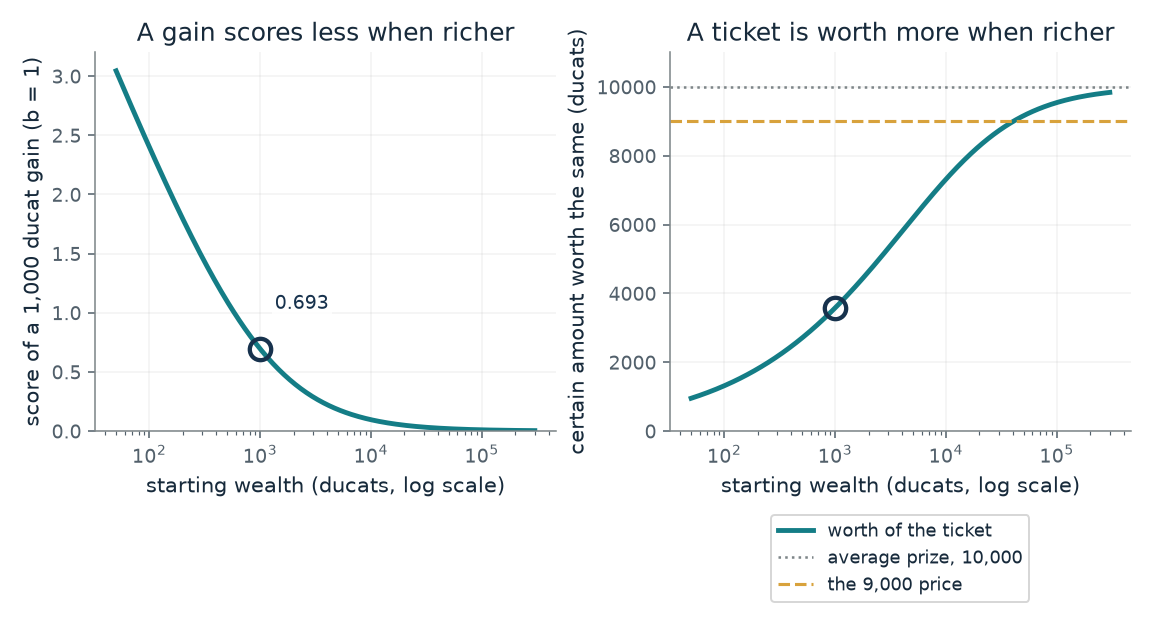

- **Score of a 1,000 ducat gain:** 0.693
- **Wealth after the gain (ducats):** 2000
- **Worth of the ticket (ducats):** 3583
- **Worth against 9,000:** below 9,000: selling at 9,000 is no mistake

Starting from 1,000 ducats, a 1,000 ducat gain scores 0.693. The ticket, which pays 0 or 20,000 with equal chances, is worth 3583 certain ducats to this holder, below 9,000: selling at 9,000 is no mistake.

Gain score = ln((1,000 + 1,000)/1,000) = 0.693. Ticket worth p solves ln(w + p) = 0.5 ln(w) + 0.5 ln(w + 20,000), so p = sqrt(w (w + 20,000)) - w = 3583.

In [2]:
figure, values, explanation = log_picture(**{'start_wealth': 1000})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does the same gain count for less when you already have more?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Starting wealth (ducats) = 100000: At 100,000 ducats the same gain scores 0.00995, about 70 times less than at 1,000. The ticket is worth about 9,540 there. It is worth exactly 9,000 at 40,500 ducats: holders with less would sell at 9,000, and holders with more would buy.

**Takeaway:** A rule that makes a gain matter less as wealth grows gives the same outcome different worth to different holders, with no change in the outcome itself.

**Why it matters:** A program given outcomes and a curve will price one ticket differently for two people. The price comes from the chosen curve and the wealth supplied, not from the outcome, so both must be checked against the person.

**In brains and behavior:** Bernoulli argued that a poor holder could sell at 9,000 without error and a rich one would buy. It was an argument, and nothing here says a brain computes a logarithm.

**In machines:** A program supplied with a wealth figure and this curve computes the worth directly. The designer chose what it counts and how sharply the curve bends; the calculation does not show the curve fits a given person.

**Where it applies:** A gain's worth is inversely proportional to existing wealth, which gives the logarithm. Both wealth amounts must be above zero. The score is not a measurement of anyone's happiness, and other curves predict the same direction.

**Check your understanding:** A holder has 1,000 ducats. What certain amount is the ticket worth under the rule, and is 9,000 above or below it?

<details><summary>Show the answer</summary>

p = sqrt(1,000 x 21,000) - 1,000 = 4,583 - 1,000, about 3,583 ducats. So 9,000 is far above its worth to this holder, and selling at 9,000 is no mistake.

</details>

*Source: Chapter 13, Wealth changes the value of a gain. Book formula (Bernoulli's rule as the chapter presents it). The 1,000 and 100,000 ducat wealth figures are the chapter's constructed examples. The ticket worth p is this companion's computation from the chapter's rule, using the chapter's ticket (0 or 20,000, equal chances) and the 9,000 price; the chapter states neither the formula for p nor the 40,500 ducat figure, and Bernoulli's argument was not a recorded sale.*

## C13-D02: Which part of the model makes a loss frame choose the gamble?

Two groups face the same final amounts but one hears gains and the other losses. A curve measured from a reference point can reproduce the majority choices, and the question is which of its features does the work.

Measured from the gift, the extra 500 is a gain for one group and a loss for the other. Square roots bend both sides, so a sure thing beats a gamble among gains and a gamble beats a sure thing among losses. Making losses count more multiplies every loss score by the same number, so it does not reorder two loss options, but it makes an even chance of gaining or losing the same amount look bad.

$$
v(x)=\begin{cases}\sqrt{x}, & x\ge 0,\\ -\lambda\sqrt{-x}, & x<0.\end{cases}
$$

**Symbols:** x: the change from the reference point, in pounds (positive for a gain, negative for a loss); v(x): the score, in arbitrary units; lambda: the loss weight: 2 in the chapter's curve, and 1 means no extra weight on losses

**Predict before looking:** Set the loss weight to 1 in the loss frame. Predict whether the model still prefers the gamble, then try the even bet and ask what the weight does there.

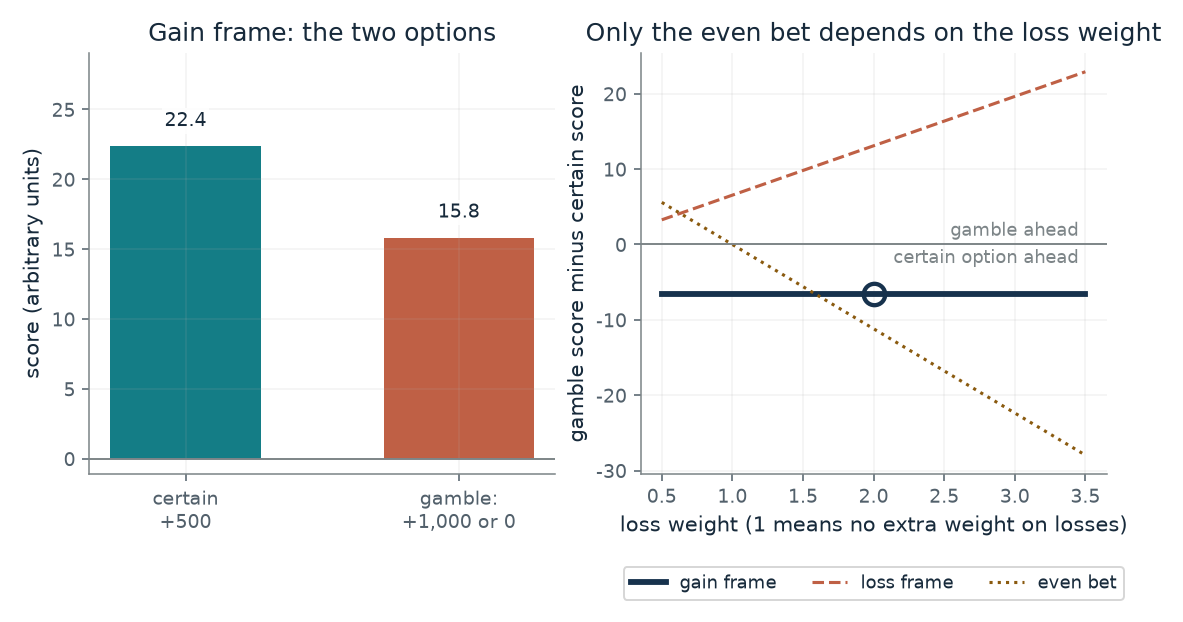

- **Score of the certain option:** 22.4
- **Score of the gamble:** 15.8
- **Model picks:** the certain option
- **Majority in the study:** certain gain (84 percent of 70 chose it)

With loss weight 2, the certain option scores 22.4 and the gamble 15.8, so the model picks the certain option. The curve is the chapter's constructed illustration, not fitted to the respondents.

sqrt(500) versus half of sqrt(1,000): 22.4 against 15.8. Scores are averaged with the stated chances, with no probability weighting.

In [3]:
figure, values, explanation = value_picture(**{'problem': 'gain frame', 'loss_weight': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Which part of the model makes a loss frame choose the gamble?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Problem = loss frame, Loss weight = 1: With no extra weight on losses the certain loss still scores about -22.4 against -15.8 for the gamble, so the gamble still wins. Raising the weight scales both loss scores by the same positive number and cannot reverse their order. The weight matters only in the even bet.

**Takeaway:** The reference point and the curve's bend produce the gain and loss framing reversal; the loss weight does its own, separate work in a bet that mixes gains and losses.

**Why it matters:** A machine that records only final amounts has already lost the framing. Giving it a reference point restores the distinction, and checking which feature produces which effect keeps a designer from crediting the wrong one.

**In brains and behavior:** The 1979 study measured hypothetical choices of different groups. It did not identify neurons computing this curve, and a program with no variable for fear or relief still produces the gain and loss pattern.

**In machines:** The machine implements the arithmetic exactly. That shows a limited computational capability, not that emotion is irrelevant to people or that the machine experiences the scores.

**Where it applies:** A reference point (the gift) and a curve that bends the same way on both sides. The study measured stated choices of different people, not neurons or one person reversing. Matching the direction of the majority does not predict the percentages or explain how people choose their reference points.

**Check your understanding:** In the even bet, at what loss weight does the model score the gamble at exactly zero, the same as the certain change of zero?

<details><summary>Show the answer</summary>

The gamble scores half of sqrt(500) minus half of the weight times sqrt(500), which is zero only when the weight is 1. Any larger weight scores it below zero, so the certain zero is preferred.

</details>

*Source: Chapter 13, Measure the change. The curve is the chapter's own constructed illustration, chosen for easy arithmetic and not estimated from the respondents. The choice problems are the 1979 hypothetical questions: 70 respondents with a gift of 1,000 pounds (84 percent chose the certain gain) and 68 with a gift of 2,000 (31 percent chose the certain loss). The even bet is the chapter's own illustration and was not put to respondents. Scores average outcomes by their chances, with no probability weighting.*

## C13-D03: How can the same food be worth something, nothing, or less than nothing?

A model body scores an outcome by how far it moves the body toward its set points. What does three units of food score when the body is hungry, full, or thirsty?

Drive adds up how far each need is from its set point. An outcome is scored by how much it shrinks that total. Food that fills a gap shrinks it, food added to a full body opens a new gap and grows it, and food does nothing to a gap in water. So reward depends on what the body lacks now.

$$
D(H_t)=\Big(\sum_{i=1}^{N}|h_i^*-h_{i,t}|^{n}\Big)^{1/m},\qquad r(H_t,K_t)=D(H_t)-D(H_t+K_t)
$$

**Symbols:** h_i^*, h_i: set point and current level of need i (food and water here, set points 10); D: drive: the combined gap from the set points; n, m: positive numbers that set how gaps combine; n = m = 1 is the chapter's illustration; K_t: the change an outcome causes (3 units of food, or of water); r: reward: drive before minus drive after

**Predict before looking:** Predict what the model scores for 3 units of food at food 10 and water 10, and whether water scores higher when water is at 4.

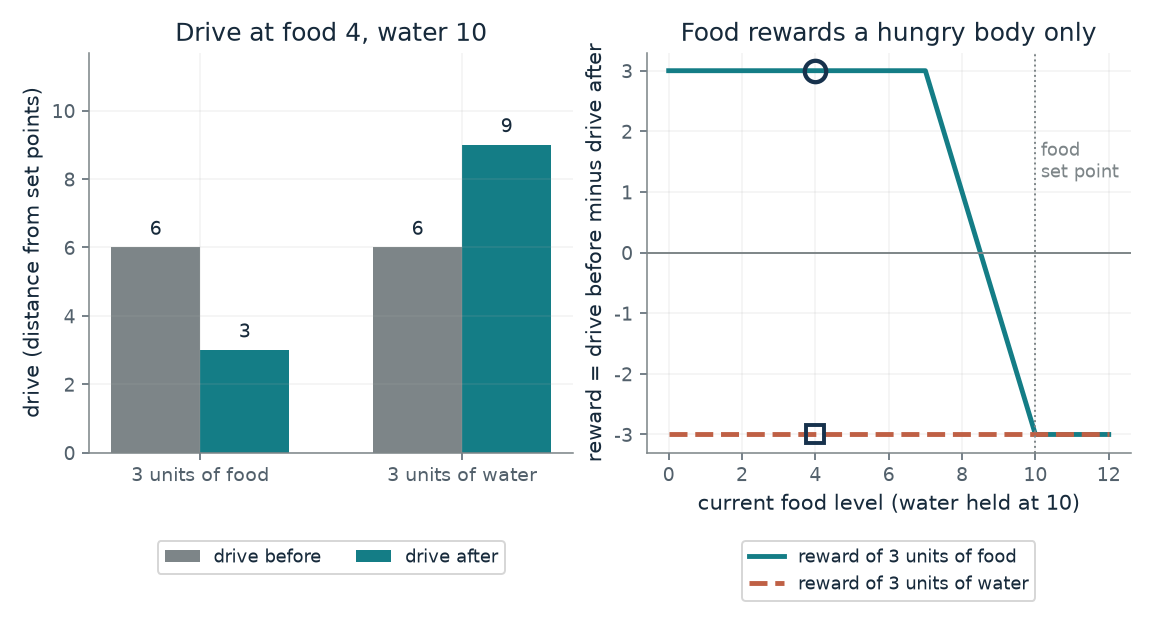

- **Drive before:** 6
- **Reward of 3 units of food:** 3
- **Reward of 3 units of water:** -3
- **Higher reward:** food

At food 4 and water 10 the model body's drive is 6. Three units of food score 3 and three units of water -3, so food scores higher. This is a constructed model, not a fit to any animal.

Set points 10 and 10; n = m = 1, drive is the sum of the gaps. Drive now = 6. After food: (7, 10) gives 3, reward 6 - 3 = 3. After water: (4, 13) gives 9, reward -3.

In [4]:
figure, values, explanation = drive_picture(**{'food': 4, 'water': 10, 'form': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How can the same food be worth something, nothing, or less than nothing?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Current food level = 10, Current water level = 10, Drive form (1: n = m = 1; 2: n = 3, m = 2) = 1: A model body at both set points scores 3 units of food at -3 (drive goes from 0 to 3). A hungry one (food 4, water 10) scores it at +3. The same outcome has opposite scores when the starting state differs.

**Takeaway:** Once the score depends on the body's state, the same outcome can reward, do nothing, or penalize, because value is the change in drive and not a fixed number attached to food.

**Why it matters:** A machine that gives food a fixed score cannot represent a changing need through that score alone. Supplying a state description and letting the score depend on it is one way to do so.

**In brains and behavior:** Rats that had learned a Y-maze with food on one side and water on the other tended to choose the side that fit their test need. The only source is a 1940 conference abstract with no counts, and the model paper did not test that maze, so this is a resemblance in direction, not a fit.

**In machines:** The equations are a specification of a designed system: given levels and set points they return a score. A designed system that scores departures from a target does not establish that a brain uses this formula.

**Where it applies:** Two needs, a fixed set point for each, and a reward defined as reduction in drive. Overshooting a set point can give a negative score. The model specifies internal levels; it does not say how a body senses or regulates its own state.

**Check your understanding:** A model body has food 10 and water 4, set points 10, with n = m = 1. What do 3 units of food and 3 units of water score?

<details><summary>Show the answer</summary>

Drive now is 6. Food takes the body to (13, 4): gaps 3 and 6, drive 9, reward 6 - 9 = -3. Water takes it to (10, 7): drive 3, reward +3. Water scores higher.

</details>

*Source: Chapter 13, Need changes the goal. Book formula (the Keramati and Gutkin homeostatic reward as the chapter presents it). The set points of 10 and the 3-unit outcome follow the chapter's constructed example, whose hungry case (food 4, water 10) gives drive 6 to 3 and reward 3, and whose full case gives drive 0 to 3 and reward -3. The second drive form (n = 3, m = 2) is the paper's regime n > m > 1, evaluated here by this companion; the chapter's n = m = 1 relaxes that restriction.*

## C13-D04: How do two scores become a predicted preference?

A model gives clip A a score of 2 and clip B a score of 1. What chance does it give that a person prefers A, and what happens if every score shifts?

Raising both scores by the same number multiplies the top and bottom of the fraction by the same factor, so it cancels. A gap of 1 gives 73 percent for the higher option, a gap of 3 gives 95 percent, and no gap gives one half. Random responses mix in a coin flip and keep the chance away from 0 and 1.

$$
P(a\succ b)=\frac{e^{r_a}}{e^{r_a}+e^{r_b}}
$$

**Symbols:** r_a, r_b: the model's scores for options a and b; e: the constant 2.718...; P(a > b): the predicted chance that a person prefers a

**Predict before looking:** Predict the chance A is preferred when the scores are 2 and 1, then predict it when both scores are 12 and 11.

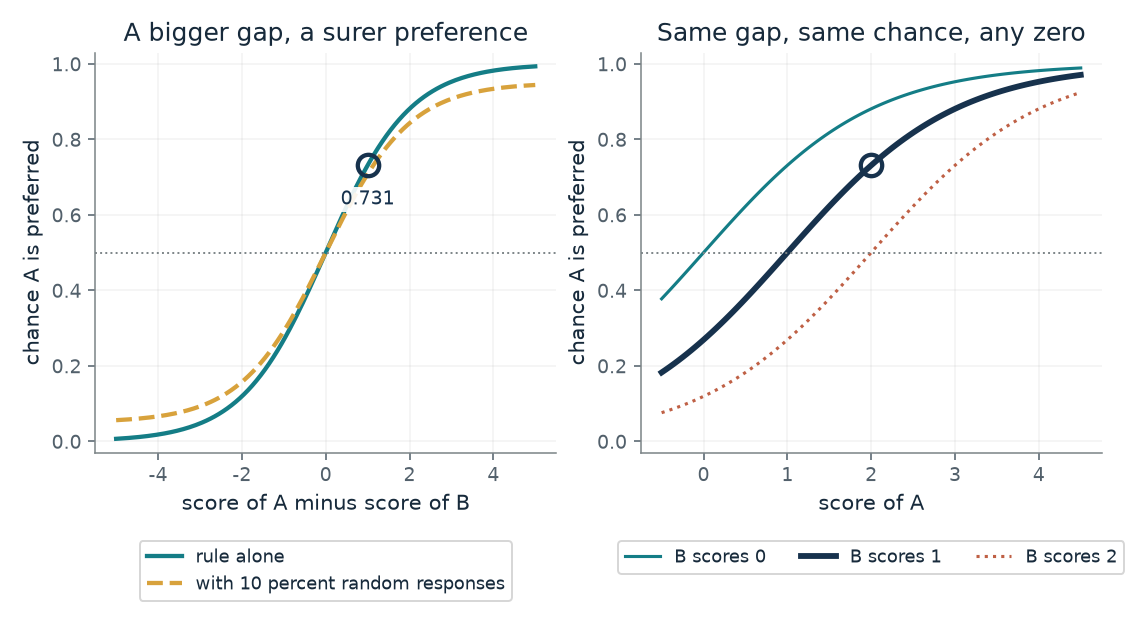

- **Score gap (A minus B):** 1
- **Chance A is preferred:** 0.731
- **Chance B is preferred:** 0.269
- **Same with 5 added to both scores:** 0.731

Scores 2 and 1 give a gap of 1 and a predicted chance of 0.731 that A is preferred. Adding the same number to both scores leaves the chance at 0.731, because only the gap matters.

Without random responses: e^2 / (e^2 + e^1) = 0.731. With a share 0 of fair-coin responses: (1 - 0) x 0.731 + 0 x 0.5 = 0.731.

In [5]:
figure, values, explanation = comparison_picture(**{'score_a': 2, 'score_b': 1, 'random_response': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How do two scores become a predicted preference?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Score of A = 2, Score of B = 1, Share of random responses = 0: The chance is e^2/(e^2 + e^1), about 0.731, and the right panel shows the same chance whenever the gap is 1, whatever the zero. Turning on 10 percent random responses pulls it toward 0.5, to about 0.708.

**Takeaway:** Only the gap between two scores sets the predicted preference, so scores have no fixed zero, and equal scores give exactly one half.

**Why it matters:** A reward learned from comparisons is determined only up to a shift. Knowing that tells a designer what the numbers can and cannot mean.

**In brains and behavior:** A person who is asked which of two clips is better produces an answer. The rule predicts the pattern of answers, not how the person's brain reaches them.

**In machines:** A reward model uses scores for clips and this rule to score its own fit to the comparisons it receives; the agent is then trained against the learned scores.

**Where it applies:** The model's scores summarize which option a person tends to choose. The rule is a model of answers, not an established account of how the brain makes them.

**Check your understanding:** Scores of 3 and 0. What chance does the rule give that A is preferred, and what is it with 10 percent random responses?

<details><summary>Show the answer</summary>

e^3/(e^3 + 1) = 20.09/21.09, about 0.953. With random responses it is 0.9 x 0.953 + 0.05, about 0.907.

</details>

*Source: Chapter 13, A machine can learn from human comparisons. Book formula with the chapter's constructed scores (2 and 1, not scores of any hopper clip). The 10 percent random-response option follows the chapter's remark that the training method allowed a 10 percent chance of a random response; reading that as a fair coin, so P is 0.9 times the rule plus 0.05, is this companion's, not the chapter's formula.*

## C13-D05: How much comparing does it take to recover a score gap?

Learning runs the other way from the preference rule: given a person's comparisons, the system adjusts scores to account for them. How close does a score gap get as comparisons accumulate?

The share of comparisons that favor A is the data, and the gap that best explains that share is the log of its odds. Few comparisons leave the share noisy, and if all go one way the best gap is infinite, so the estimate is undefined. More comparisons narrow the spread, and larger gaps are easier to see because the shares are further from one half.

$$
\hat g=\ln\frac{f}{1-f},\qquad \text{typical error}\approx\frac{1}{\sqrt{n\,p(1-p)}}
$$

**Symbols:** g-hat: the estimated score gap between two options; f: the share of the n comparisons in which the first option was preferred; p: the true chance the first option is preferred, from the rule in the previous demonstration; n: the number of comparisons

**Predict before looking:** Predict whether 10 comparisons recover a gap of 1 as well as 100 do, and how much 900 improve on 100.

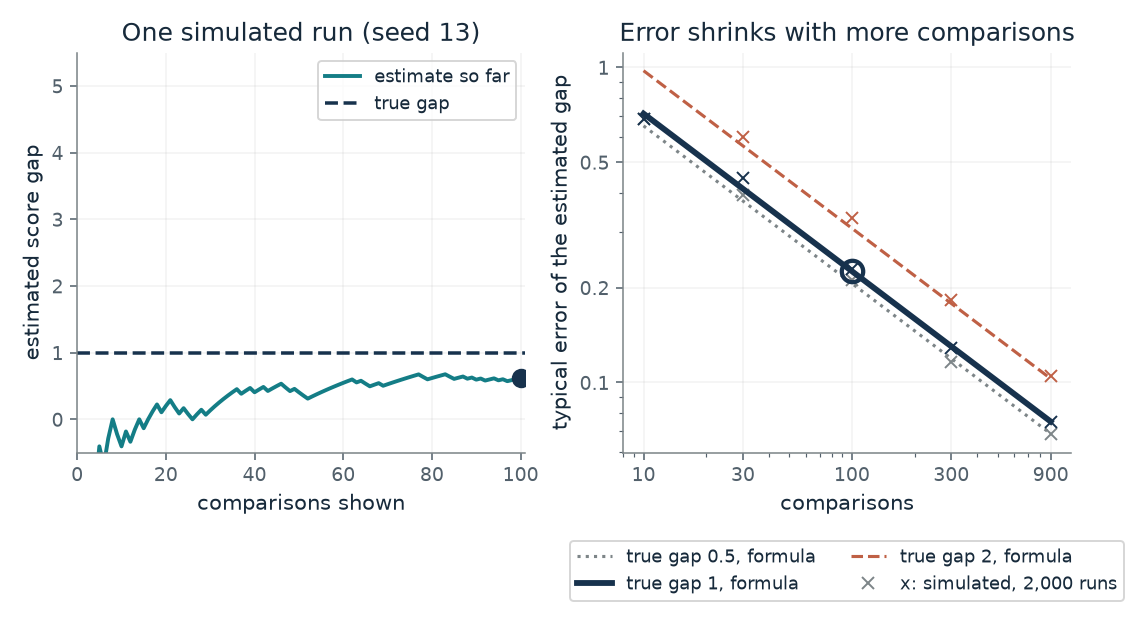

- **Share preferring A (this run):** 0.65
- **Estimated score gap:** 0.619
- **True score gap:** 1
- **Typical error (formula):** 0.226

After 100 simulated comparisons the preferred answer won 65, giving an estimated gap of 0.619 against a true gap of 1. The formula puts the typical error at 0.226; this is a simulation with a made-up true gap, not a measurement.

Estimated gap = ln(f / (1 - f)) with f = 65/100 = 0.65. Typical error = 1/sqrt(n p (1 - p)) with p = 0.731, n = 100: 0.226. Repeating 2000 runs gave an rms error of 0.23.

In [6]:
figure, values, explanation = learn_picture(**{'true_gap': 1, 'comparisons': 100})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How much comparing does it take to recover a score gap?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At True score gap = 1, Comparisons = 100: With 100 comparisons and a true gap of 1 the typical error is about 0.23. Nine times the comparisons cut it by a factor of 3, so 900 comparisons leave an error of about 0.075.

**Takeaway:** A score is learned from comparisons by raising the likelihood of the answers received, and the error shrinks slowly, in proportion to one over the square root of the number of comparisons.

**Why it matters:** A person can judge examples without assigning every clip a number, and the machine can use those judgments. But how many are needed depends on how large the difference is, and the learned scores say nothing beyond the person's answers.

**In brains and behavior:** A person supplies the comparisons. The simulation has no person, only a coin with a chosen bias, so it says nothing about how people judge.

**In machines:** The estimate is a computation on the comparisons received. A system that matches a person's comparisons has learned a score for their answers, which does not show that it understands or experiences the goal.

**Where it applies:** One pair of options, independent comparisons, a fixed true gap and no random responses or mislabeling. A learned score can fail on behavior unlike what the person evaluated, which this demonstration does not test.

**Check your understanding:** The true gap is 2, so A is preferred with chance 0.881. About how large is the typical error after 100 comparisons?

<details><summary>Show the answer</summary>

1/sqrt(100 x 0.881 x 0.119) = 1/sqrt(10.5), about 0.31.

</details>

*Source: Chapter 13, A machine can learn from human comparisons. A seeded simulation of this companion's, with a made-up true gap (0.5, 1 or 2) and the rule of the previous demonstration. The estimate is the maximum likelihood gap for one pair, and the error formula is the standard large-sample one; neither is stated in the chapter. It is a simulation, not a measurement, and not the hopper study, which reported that 900 queries in under an hour taught a backflip by training a reward model with a neural network on clips.*

## Bring it to your own question

Ask what the outcomes are measured from (wealth, a reference point, a bodily state, or a person's comparisons), then choose the matching card: the logarithm when the same gain should matter less to someone who has more, the reference-point curve when framing as gain or loss may change the choice, the drive model when the body's needs change a goal's worth, the comparison rule when only a person can say which of two outcomes is better. Say which part of the rule does the work, what the person or designer chose, and what choices would show the rule is wrong for this case.

Use the `mmi-ch13-what-matters` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.